# 04 — 4DVarNet 2-D Demo

Demonstrates `FourDVarNet2D` on synthetic 2-D spatiotemporal data.

In [1]:
# (NNX removed in Epic 0 — vardax is now equinox-native)
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import vardax
from vardax import Batch2D, FourDVarNet2D

## Generate synthetic 2-D data

In [2]:
key = jax.random.PRNGKey(0)
B, T, H, W = 2, 5, 16, 16
k1, k2 = jax.random.split(key)
target = jax.random.normal(k1, (B, T, H, W))
mask = (jax.random.uniform(k2, (B, T, H, W)) > 0.4).astype(jnp.float32)
batch = Batch2D(input=target * mask, mask=mask, target=target)

print(f"Input shape: {batch.input.shape}")

Input shape: (2, 5, 16, 16)


## Create model

In [3]:
model = FourDVarNet2D(
    n_time=T,
    height=H,
    width=W,
    latent_dim=16,
    hidden_dim=8,
    n_solver_steps=3,
    key=jax.random.PRNGKey(1),
)

out = model(batch)
print(f"Output shape: {out.shape}")

mse = float(jnp.mean((out - target) ** 2))
print(f"MSE (untrained): {mse:.4f}")

Output shape: (2, 5, 16, 16)
MSE (untrained): 0.3954


## Visualise a single time step

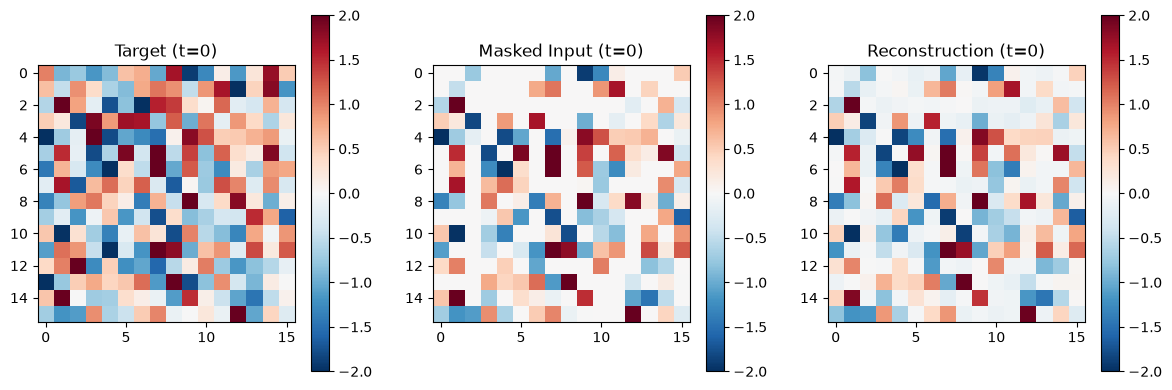

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, (ax, title) in enumerate(zip(axes, ["Target", "Masked Input", "Reconstruction"])):
    data = [target, batch.input, out][i]
    im = ax.imshow(data[0, 0], cmap="RdBu_r", vmin=-2, vmax=2)
    ax.set_title(f"{title} (t=0)")
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()